In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT / 'src'))

from cevns_pyeft.kernels.basis import coeff_vector_from_triplets, li2026_left_basis_current
from cevns_pyeft.kernels.reconstruction import reconstruct_real_events_from_full_kernel
from cevns_pyeft.experiments.coherent.slow_counts_csi2021 import slow_counts_csi2021

REFERENCE_DIR = ROOT / 'tests' / 'reference_fast_split'
RESPONSES = ROOT / 'data' / 'responses' / 'responses_all.json'
STEM = 'csi2021'
EXPERIMENT = 'CsI2021'
RTOL, ATOL = (2.5e-2, 8.0e-1)


In [2]:
basis = li2026_left_basis_current()
coeff = coeff_vector_from_triplets(basis, {}, include_sm=True)
full_kernel = np.load(REFERENCE_DIR / f'{STEM}_full_kernel.npy')
metadata = __import__('json').loads((REFERENCE_DIR / f'{STEM}_metadata.json').read_text())
raw = reconstruct_real_events_from_full_kernel(full_kernel, coeff)
channel_summed = raw.sum(axis=2)
target_index = metadata['targets'].index('CsI') if 'CsI' in metadata['targets'] else 0
flavor_index = {flavor: metadata['source_flavors'].index(flavor) for flavor in ('mu', 'e', 'mub')}
fast_counts = {flavor: channel_summed[target_index, flavor_index[flavor]] for flavor in ('mu', 'e', 'mub')}
fast_counts['total'] = fast_counts['mu'] + fast_counts['e'] + fast_counts['mub']
slow_counts = slow_counts_csi2021(RESPONSES, include_sm=True, n_er=3, n_enu=6, n_pe_bin=3)['counts_per_bin']
pe_bins = np.asarray(metadata['pe_bins'], dtype=float)
centers = 0.5 * (pe_bins[:-1] + pe_bins[1:])
print({k: np.asarray(v, dtype=float) for k, v in fast_counts.items()})


{'mu': array([2.86769563e-046, 1.43384782e-046, 2.68891486e-070, 1.39757563e-094,
       5.13619865e-119, 3.31634732e-143, 3.10911317e-192, 2.83309187e-241,
       3.85405567e-290]), 'e': array([1.30095587e-07, 2.39701070e-04, 1.96427806e-02, 2.82001531e-01,
       1.39013983e+00, 7.83787420e+00, 7.42571072e+00, 2.43148615e+00,
       4.35938385e-01]), 'mub': array([5.30729984e-07, 9.77858047e-04, 8.01317054e-02, 1.15040025e+00,
       5.67090532e+00, 3.19732685e+01, 3.02915857e+01, 9.91862701e+00,
       1.77828487e+00]), 'total': array([6.60825571e-07, 1.21755912e-03, 9.97744860e-02, 1.43240178e+00,
       7.06104515e+00, 3.98111427e+01, 3.77172964e+01, 1.23501132e+01,
       2.21422325e+00])}


In [3]:
fast_total = np.asarray(fast_counts['total'], dtype=float)
slow_total = np.asarray(slow_counts['total'], dtype=float)
assert fast_total.shape == slow_total.shape == centers.shape
assert np.issubdtype(fast_total.dtype, np.floating)
assert np.all(np.isfinite(fast_total))
assert np.all(np.isfinite(slow_total))
np.testing.assert_allclose(fast_total, slow_total, rtol=RTOL, atol=ATOL)
max_abs_diff = float(np.max(np.abs(fast_total - slow_total)))
summary = {
    'experiment': EXPERIMENT,
    'bins': int(fast_total.size),
    'fast_total': float(np.sum(fast_total)),
    'slow_total': float(np.sum(slow_total)),
    'max_abs_diff': max_abs_diff,
    'status': 'PASS',
}
summary


{'experiment': 'CsI2021',
 'bins': 9,
 'fast_total': 100.68721513300288,
 'slow_total': 100.35348980561156,
 'max_abs_diff': 0.779600012135667,
 'status': 'PASS'}

{'experiment': 'CsI2021', 'bins': 9, 'fast_total': 100.68721513300288, 'slow_total': 100.35348980561156, 'max_abs_diff': 0.779600012135667, 'status': 'PASS'}


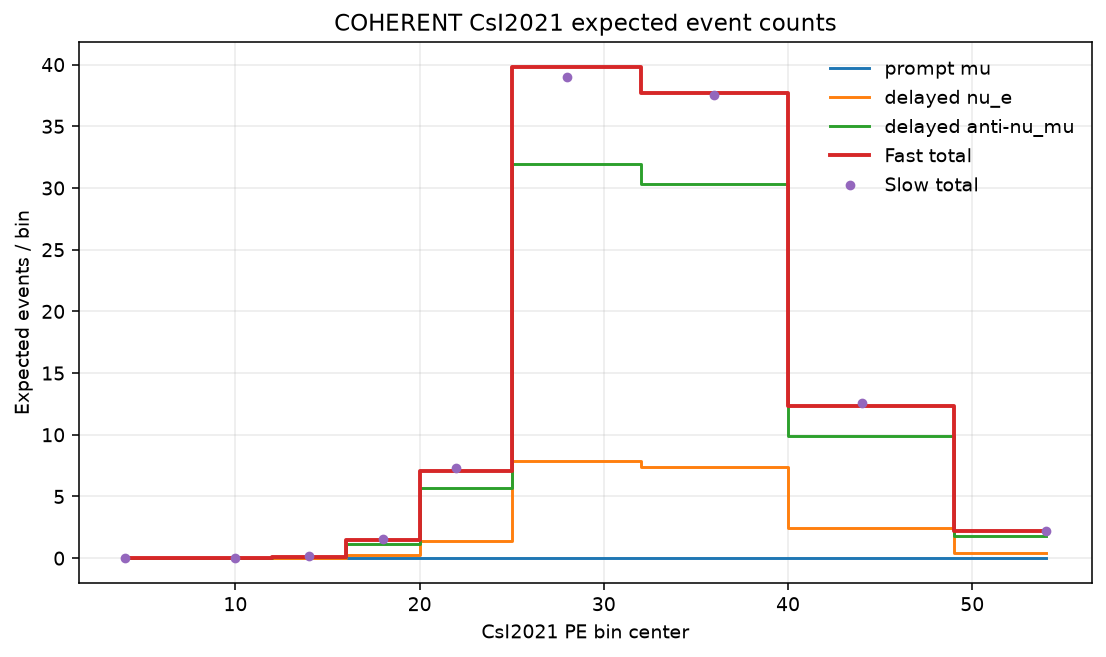

In [4]:
fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=140)
ax.step(centers, fast_counts['mu'], where='mid', label='prompt mu')
ax.step(centers, fast_counts['e'], where='mid', label='delayed nu_e')
ax.step(centers, fast_counts['mub'], where='mid', label='delayed anti-nu_mu')
ax.step(centers, fast_counts['total'], where='mid', linewidth=2.0, label='Fast total')
ax.plot(centers, slow_counts['total'], 'o', markersize=4.0, label='Slow total')
ax.set_title('COHERENT CsI2021 expected event counts')
ax.set_xlabel('CsI2021 PE bin center')
ax.set_ylabel('Expected events / bin')
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
print(summary)
